## NBA Points per Minute Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only - not a production pipeline yet

**- Last Updated:** 10/26/26

### Question

**How accurately can we predict an NBA player's points per minute in their next game,
and can XGBoost beat last-game points per minute, the season-to-date average, and an EWMA Last 10 of recent points per minute?**

### A/A'/B Experiment

**Baseline model:** EWMA for last 10 games

- MAE: 0.1862	

**Cloned and retrained baseline model:** XGBoost Model
- MAE: 0.1772

**Cloned baseline model with the new change(list the type of change(s)):** 

new feature set: This run (15): pts_per_min_ewm_hl_10, fga_per_min_10, fta_per_min_10, fg3a_per_min_10, ts_pct_10, season_pts_per_min, player_fga_share_10, usg_wmean_10, ppm_sd_10, starting, current_team_pts_per_min, opp_def_rating_mean_10, opp_pace_10, minutes_ewm_10, min_sd_10

Dropped (7): ppm_trim_mean_20, pts_per_min_mean_vs_opp, fga_per_min_mean_vs_opp, fta_per_min_mean_vs_opp, fg3a_per_min_mean_vs_opp, ppm_unstable, min_mean_10



### Setup and Configurations


In [94]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "points_xgb").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/points/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from points_xgb.paths import ensure_repo_on_path, repo_root

ensure_repo_on_path()

from points_xgb import (
    ARTIFACT_STEM,
    HOLDOUT_SEASON,
    ID_COLS,
    LAG_COL,
    N_BOOT,
    PREDICTIONS_PATH,
    PTS_FEATURES,
    QUANTILES,
    RATE_CAP,
    RATE_SPEC,
    RATE_TIERS,
    ROLE_COL,
    SEED,
    TAIL_SIDECAR,
    TARGET_COL,
    XGB_PARAMS,
    apply_train_tukey,
    assert_no_leak,
    assign_rate_target,
    build_miss_frame,
    build_model_frame,
    build_oos_predictions,
    calibrated_tail_frame,
    calibration_table,
    compare_to_baselines,
    data_quality,
    exploratory_metadata,
    feature_consensus,
    feature_missingness,
    feature_outlier_table,
    fit_rate_offsets,
    fold_base_knots,
    format_data_quality,
    format_rate_outliers,
    holdout_calibrated,
    holdout_point_distribution,
    holdout_role_quantiles,
    interval_sharpness,
    load_regular_season,
    loaded_holdout_scores,
    mean_absolute_shap,
    miss_view,
    missingness_summary,
    monotone_shift,
    nested_offset_backtest,
    oof_leakage_table,
    oof_player_games,
    permutation_importance_table,
    plot_missingness,
    plot_rate,
    plot_shap,
    positive_minutes,
    predicted_rate_tiers,
    quantile_calibration,
    quantile_crossing,
    rate_outlier_summary,
    row_pinball,
    rate_payload,
    regular_season_blocks,
    role_reading,
    rotation_team_games,
    score_predictions,
    season_coverage,
    season_missingness,
    slice_score,
    tail_calibration_rows,
    top_rate_rows,
    wis_values,
    write_oos_predictions,
)
from models.shared.analysis import analyze_correlations, run_feature_ablation
from models.shared.artifacts import load_model_bundle, save_model_bundle
from models.shared.conformal import apply_offsets
from models.shared.metrics import paired_date_bootstrap
from models.shared.minutes_sampler import tail_miss_rates, within_miss_rate_band
from models.shared.ppm_sampler import build_tail_tables, save_tail_sidecar
from models.shared.splits import date_walk_forward_folds, prepare_splits
from models.shared.train import evaluate_holdout, run_walk_forward

ROOT = repo_root()
pd.set_option("display.max_columns", None)


In [66]:
print(f"Holdout season: {HOLDOUT_SEASON}")
print(f"Rate cap: {RATE_CAP}")
print(f"Quantiles: {QUANTILES}")

Holdout season: 2026-27
Rate cap: 2.0
Quantiles: [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


### Data


In [67]:
df = load_regular_season(ROOT)
df.sample(5)

,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
81102,2022-23,1630202,Payton Pritchard,Payton,1610612738,BOS,Boston Celtics,0022200772,2023-02-01T00:00:00,BOS vs. BKN,W,16.150000,2,5,0.4,1,4,0.25,0,0,0.00,2,0,2,2,1,0,0,0,1,0,5,8,9.4,0,0,10.0,11.0,1,16:09,1,113.3,111.1,111.1,90.1,91.4,91.4,23.2,19.7,19.7,0.143,2.0,25.0,0.125,0.000,0.057,12.5,12.5,0.500,0.500,0.143,0.149,105.27,105.51,87.93,105.51,0.041,36,2.0,5.0,Boston,BOS,celtics,Payton,Pritchard,P. Pritchard,payton-pritchard,,,11,16.150000,4.53,1.28,4,0,4,36,1,0,28,2,0,0,0.0,2,5,0.400,0.4,1,1,1.000,53,92,0.576,26,54,0.481,7,10,0.700,11,46,57,28,12.0,4,4,1,13,12,139,43.0,142.7,141.8,98.0,98.0,44.7,43.9,0.528,2.33,20.3,0.300,0.889,0.638,0.122,0.717,0.721,97.7,98.0,81.67,98,0.666,1610612751,36,88,0.409,9,39,0.231,15,18,0.833,5,27,32,19,7.0,8,1,4,12,13,96,-43.0,98.0,98.0,142.7,141.8,-44.7,-43.9,0.528,2.71,15.4,0.111,0.700,0.362,0.071,0.460,0.500,97.7,98.0,81.67,98,0.334,Regular Season,PG,224.0,-9.0,-9.0,0
2365,2019-20,1628976,Wendell Carter Jr.,Wendell,1610612741,CHI,Chicago Bulls,0021900946,2020-03-08T00:00:00,CHI @ BKN,L,28.340000,2,5,0.4,0,0,0.00,3,4,0.75,0,3,3,1,1,0,0,0,3,4,7,-12,11.1,0,0,11.0,12.0,1,28:20,1,102.8,100.0,100.0,119.9,120.3,120.3,-17.1,-20.3,-20.3,0.050,1.0,11.1,0.000,0.158,0.059,11.1,11.4,0.400,0.518,0.123,0.126,98.78,99.93,83.27,99.93,0.027,59,2.0,5.0,Chicago,CHI,bulls,Wendell,Carter Jr.,W. Carter Jr.,wendell-carter-jr,C,,34,28.340000,3.88,1.97,3,6,9,35,0,0,27,1,1,2,0.5,1,3,0.333,0.4,6,7,0.857,39,92,0.424,12,34,0.353,17,25,0.680,5,26,31,23,7.0,14,3,5,31,24,107,-3.0,101.9,101.9,103.7,105.8,-1.8,-3.9,0.590,3.29,16.9,0.140,0.743,0.370,0.067,0.489,0.519,105.5,104.5,87.08,105,0.444,1610612751,32,64,0.500,11,30,0.367,35,41,0.854,5,45,50,21,29.0,4,5,3,24,31,110,3.0,103.7,105.8,101.9,101.9,1.8,3.9,0.656,0.72,15.7,0.257,0.860,0.630,0.279,0.586,0.670,105.5,104.5,87.08,104,0.556,Regular Season,C,218.5,-6.0,6.0,1
76168,2022-23,1629006,Josh Okogie,Josh,1610612756,PHX,Phoenix Suns,0022201013,2023-03-11T00:00:00,PHX vs. SAC,L,34.955000,4,10,0.4,3,6,0.50,4,5,0.80,0,1,1,0,1,1,1,0,1,3,15,1,21.2,0,0,23.0,22.0,1,34:57,1,112.8,111.5,111.5,110.4,108.9,108.9,2.3,2.7,2

In [68]:
print(format_data_quality(data_quality(df)))

Number of rows : 177707
Number of columns: 190
Number of Unique Players: 1214
Number of Unique Games: 8332
Total number of duplicates: 0
Missing points: 0
Missing minutes: 0
Zero-minute rows: 13
Median points: 9.0
Mean points: 10.626
Median points per minute (appearances): 0.409
Mean points per minute (appearances): 0.428
Max raw points per minute: 30.000


### Features


In [69]:
df = build_model_frame(df)

In [70]:
import points_xgb.config as points_config

# First run. Add or remove names here. Anything in the package list that is
# not in this list is dropped for the run.
PTS_FEATURES = [
    # Scoring rate
    "pts_per_min_ewm_hl_10",
    "fga_per_min_10",
    "fta_per_min_10",
    "fg3a_per_min_10",
    "ts_pct_10",
    "season_pts_per_min",

    # Offensive role and opportunity
    "player_fga_share_10",
    "usg_wmean_10",
    "ppm_sd_10",
    "starting",

    # Game environment
    "current_team_pts_per_min",
    "opp_def_rating_mean_10",
    "opp_pace_10",

    # minutes
    "minutes_ewm_10",
    "min_sd_10"
]

PLAY_FEATURES = [
    name for name in PTS_FEATURES if name not in points_config.PTS_FEATURES
]
DROP_FEATURES = [
    name for name in points_config.PTS_FEATURES if name not in PTS_FEATURES
]

if len(PTS_FEATURES) != len(set(PTS_FEATURES)):
    raise ValueError(f"duplicate features: {PTS_FEATURES}")

assert_no_leak(PTS_FEATURES)
missing = [column for column in PTS_FEATURES if column not in df.columns]
if missing:
    raise KeyError(f"Rate features missing from the panel: {missing}")
print(f"This run ({len(PTS_FEATURES)}): {', '.join(PTS_FEATURES)}")
print(f"Dropped ({len(DROP_FEATURES)}): {', '.join(DROP_FEATURES) if DROP_FEATURES else '(none)'}")
print(f"Playing: {', '.join(PLAY_FEATURES) if PLAY_FEATURES else '(none)'}")
print(f"Number of nulls: {int(df[PTS_FEATURES].isna().sum().sum())}")


This run (15): pts_per_min_ewm_hl_10, fga_per_min_10, fta_per_min_10, fg3a_per_min_10, ts_pct_10, season_pts_per_min, player_fga_share_10, usg_wmean_10, ppm_sd_10, starting, current_team_pts_per_min, opp_def_rating_mean_10, opp_pace_10, minutes_ewm_10, min_sd_10
Dropped (7): ppm_trim_mean_20, pts_per_min_mean_vs_opp, fga_per_min_mean_vs_opp, fta_per_min_mean_vs_opp, fg3a_per_min_mean_vs_opp, ppm_unstable, min_mean_10
Playing: (none)
Number of nulls: 29577


### Train/validation/test design


In [71]:
df = positive_minutes(df)
df = assign_rate_target(df)
print(f"After filtering appearances: {len(df):,} rows")
print(df[TARGET_COL].describe().round(3))

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=PTS_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=[
        "minutes",
        "pts",
        "pts_per_min_lag_1",
        "season_pts_per_min_mean",
        "pts_per_min_ewm_hl_10",
    ],
)
ppm_df = splits["ppm_df"]
ppm_holdout = splits["ppm_holdout"]
print(f"Train pool (excl. {HOLDOUT_SEASON}) : {len(ppm_df):,} rows")
print(f"Holdout   ({HOLDOUT_SEASON})        : {len(ppm_holdout):,} rows")

ppm_df, fence_low, fence_high, n_dropped = apply_train_tukey(ppm_df)
X = ppm_df[splits["features"]].copy()
y = ppm_df[TARGET_COL]
print(
    f"Train Tukey fence [{fence_low:.2f}, {fence_high:.2f}]: "
    f"dropped {n_dropped:,} extreme rates"
)
print(f"Train pool after outlier drop: {len(ppm_df):,} rows")
print(f"Holdout still includes every appearance: {len(ppm_holdout):,} rows")


After filtering appearances: 177,679 rows
count    177679.000
mean          0.427
std           0.286
min           0.000
25%           0.229
50%           0.409
75%           0.597
max           2.000
Name: pts_per_min, dtype: float64
Train pool (excl. 2026-27) : 176,710 rows
Holdout   (2026-27)        : 969 rows
Date range (train)   : 2019-10-22 → 2026-04-12
Date range (holdout) : 2026-10-20 → 2026-10-25
Train pool (excl. 2026-27) : 176,710 rows
Holdout   (2026-27)        : 969 rows
Train Tukey fence [-0.32, 1.15]: dropped 2,397 extreme rates
Train pool after outlier drop: 174,313 rows
Holdout still includes every appearance: 969 rows


### EDA


Appearance rows: 177,679
Features with a null: 14 / 15
Rows with any null feature: 12,927 (7.3%)


,n_missing,pct_missing
ppm_sd_10,9502,5.35
season_pts_per_min,4336,2.44
current_team_pts_per_min,2755,1.55
min_sd_10,2390,1.35
ts_pct_10,1447,0.81
pts_per_min_ewm_hl_10,1214,0.68
fga_per_min_10,1214,0.68
fta_per_min_10,1214,0.68
fg3a_per_min_10,1214,0.68
player_fga_share_10,1214,0.68


,ppm_sd_10,season_pts_per_min,current_team_pts_per_min,min_sd_10,ts_pct_10,pts_per_min_ewm_hl_10,fga_per_min_10,fta_per_min_10,fg3a_per_min_10,player_fga_share_10,usg_wmean_10,minutes_ewm_10,opp_def_rating_mean_10,opp_pace_10
season_year,,,,,,,,,,,,,,
2019-20,8.6,2.4,2.6,4.7,2.7,2.4,2.4,2.4,2.4,2.4,2.4,2.4,1.4,1.4
2020-21,5.4,2.3,1.4,0.9,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0
2021-22,4.6,2.3,1.6,1.0,0.7,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0
2022-23,3.6,2.1,1.1,0.7,0.4,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.0,0.0
2023-24,5.3,2.2,1.3,0.8,0.5,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2024-25,5.8,2.2,1.2,0.8,0.5,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2025-26,4.6,2.2,1.3,0.8,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2026-27,9.2,41.3,13.5,7.2,5.0,4.3,4.3,4.3,4.3,4.3,4.3,4.3,0.0,0.0


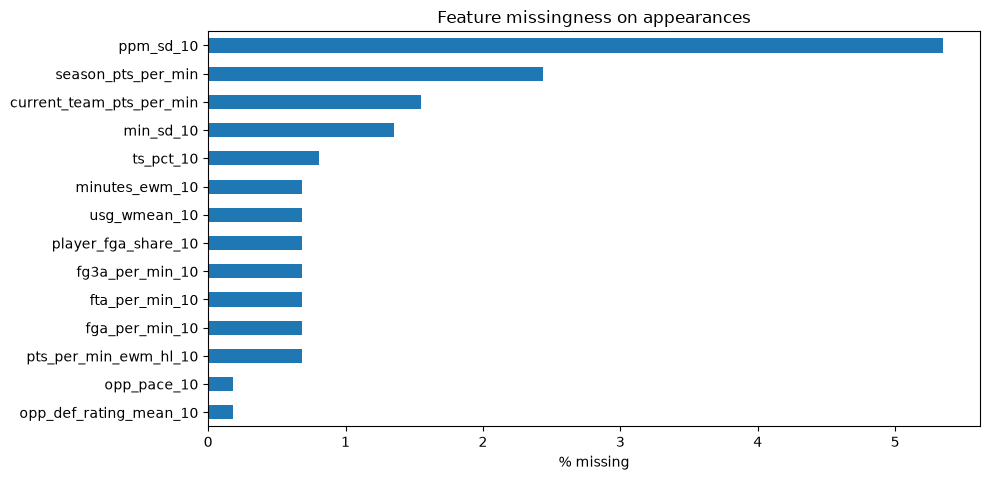

In [72]:
miss = feature_missingness(df, PTS_FEATURES)
print(missingness_summary(df, PTS_FEATURES))
display(miss)
season_miss = season_missingness(df, miss)
if not season_miss.empty:
    display(season_miss.round(3))
plot_missingness(miss)
plt.show()


n=177,679  min=0.00  p50=0.41  max=2.00
Tukey fence [-0.32, 1.15]  outside=2,418 (1.4%)
Rows at the 2 points-per-minute cap: 262


,season_year,game_date,player_name,pts_per_min,starting
3360,2019-20,2019-11-13,Terance Mann,2.0,0
3809,2019-20,2019-11-16,Gary Clark,2.0,0
4406,2019-20,2019-11-20,Oshae Brissett,2.0,0
4951,2019-20,2019-11-23,Jordan Bone,2.0,0
5030,2019-20,2019-11-24,Isaac Bonga,2.0,0
7238,2019-20,2019-12-08,Mike Muscala,2.0,0
7439,2019-20,2019-12-09,Tony Bradley,2.0,0
8747,2019-20,2019-12-18,Ryan Broekhoff,2.0,0


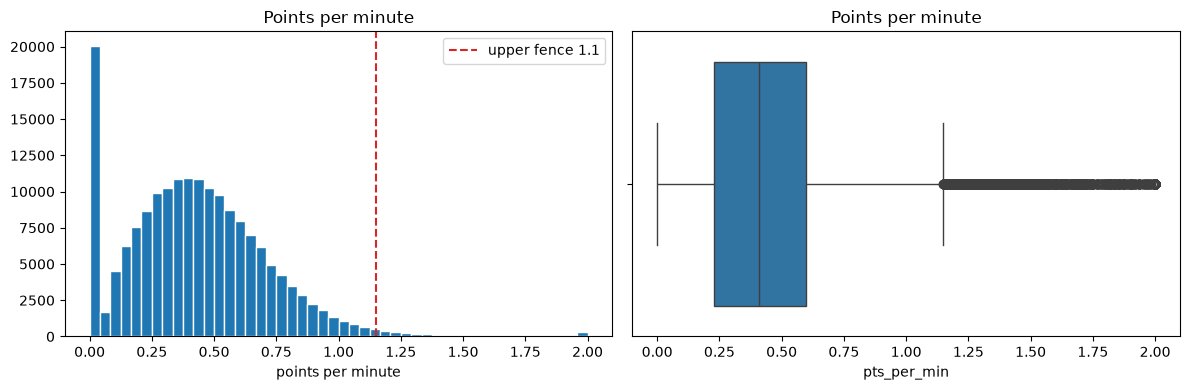

,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,ts_pct_10,176232,3.47,0.35,0.79,0.00,0.57,1.50
1,current_team_pts_per_min,174924,3.22,0.08,0.77,0.00,0.42,3.30
2,season_pts_per_min,173343,3.05,0.04,0.81,0.00,0.41,3.30
3,fta_per_min_10,176465,2.85,-0.07,0.23,0.00,0.07,1.43
4,pts_per_min_ewm_hl_10,176465,2.66,0.05,0.81,0.00,0.42,3.30
5,ppm_sd_10,168177,2.39,0.03,0.35,0.00,0.19,0.85
6,min_sd_10,175289,1.93,-0.23,11.22,0.00,5.32,28.39
7,usg_wmean_10,176465,1.40,0.03,0.33,0.00,0.18,1.00
8,opp_def_rating_mean_10,177359,0.82,99.37,126.53,85.00,112.96,133.00
9,fga_per_min_10,176465,0.78,0.04,0.64,0.00,0.34,3.33


In [73]:
outlier_stats = rate_outlier_summary(df, TARGET_COL, RATE_CAP)
print(format_rate_outliers(outlier_stats))
display(top_rate_rows(df, TARGET_COL))
plot_rate(df, TARGET_COL, outlier_stats["fence_high"])
plt.show()
display(feature_outlier_table(df, PTS_FEATURES))


In [74]:
coverage = season_coverage(df, PTS_FEATURES)
display(coverage)

,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22387,529,1059,2019-10-22,2020-08-14,91.1,0.40
2020-21,23053,540,1080,2020-12-22,2021-05-16,92.5,0.14
2021-22,26035,605,1230,2021-10-19,2022-04-10,93.4,0.14
2022-23,25892,539,1230,2022-10-18,2023-04-09,94.5,0.10
2023-24,26393,572,1230,2023-10-24,2024-04-14,92.8,0.13
2024-25,26302,569,1230,2024-10-22,2025-04-13,92.3,0.13
2025-26,26648,582,1230,2025-10-21,2026-04-12,93.5,0.12
2026-27,969,400,43,2026-10-20,2026-10-25,54.8,1.07


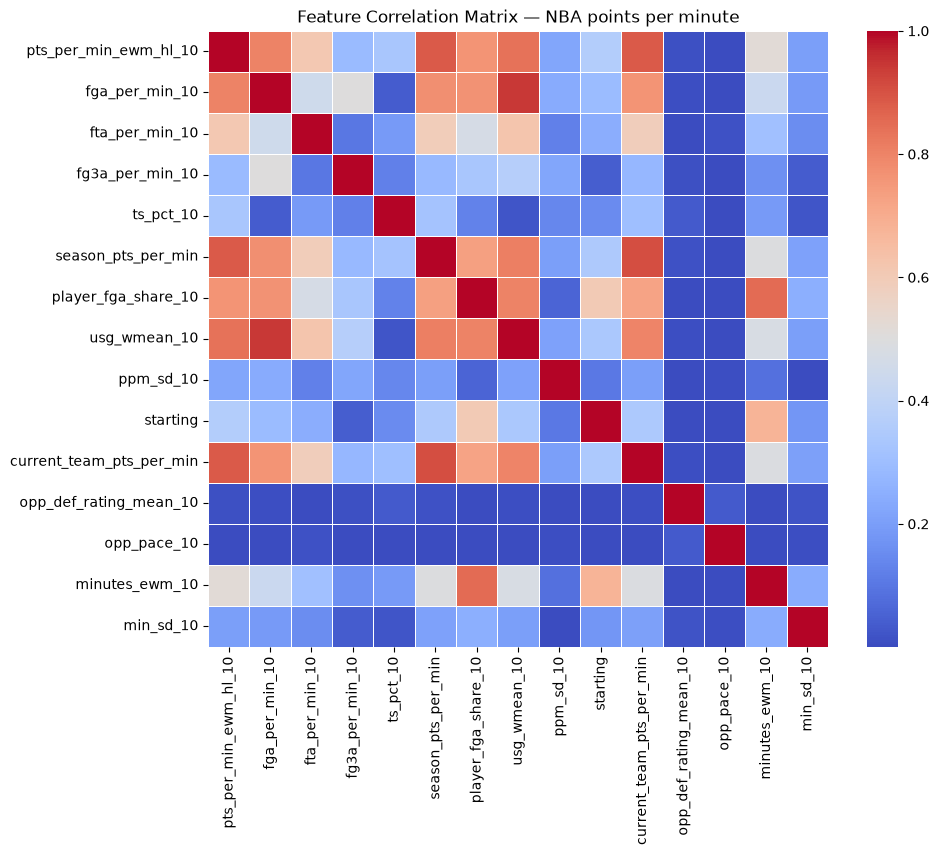

--- High Correlation Report (Threshold > 0.95) ---
No features exceed the correlation threshold.


[]

In [75]:
correlated_features = analyze_correlations(
    df, PTS_FEATURES, title="Feature Correlation Matrix — NBA points per minute"
)
correlated_features


### Models


In [76]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

# import importlib
# import models.shared.train as train

# importlib.reload(train)
# tune_xgb_quantile = train.tune_xgb_quantile

# result = tune_xgb_quantile(X, y, n_trials=50, n_splits=4)
# XGB_PARAMS = result["best_params"]


In [77]:
# Primary evaluation: production-style walk-forward
wf = run_walk_forward(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=RATE_TIERS,
    quantiles=QUANTILES,
    n_folds=5,
    target_col=TARGET_COL,
)

# Downstream:
# - Fit conformal offsets on wf["oof"]
# - Compare against baselines
# - Inspect per-fold pinball and coverage
# - Evaluate the holdout once

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]



── Phase 2: Walk-Forward Validation (XGBoost, date-based) ──────
Unique game dates in pool : 1106
Training window           : 553 dates (~50%)
Step size                 : 111 dates (~10%)

WF fold 1  (2023-01-26 → 2023-12-12)
  n=17363
  pinball  | q0.05=0.018  q0.10=0.032  q0.20=0.056  q0.30=0.073  q0.40=0.084  q0.50=0.088  q0.60=0.086  q0.70=0.079  q0.80=0.064  q0.90=0.041  q0.95=0.024
  coverage | 80%=80.9% (target 80%)  90%=91.0% (target 90%)
  Starters   | n= 8259 | pinball q50: 0.075 | 80% coverage: 79.4%
  Bench      | n= 9104 | pinball q50: 0.099 | 80% coverage: 82.3%
  minute tiers by predicted q50
  <0.30      | n= 4122 | pinball q50: 0.096 | 80% coverage: 84.5%
  0.30-0.50  | n= 9227 | pinball q50: 0.087 | 80% coverage: 80.2%
  0.50-0.70  | n= 3111 | pinball q50: 0.081 | 80% coverage: 78.9%
  0.70+      | n=  903 | pinball q50: 0.081 | 80% coverage: 79.0%

WF fold 2  (2023-12-12 → 2024-04-09)
  n=17899
  pinball  | q0.05=0.017  q0.10=0.032  q0.20=0.055  q0.30=0.072  q0.40=0

### Conformal calibration

Walk-forward out-of-fold rows only. Nothing here is fit on the 2025-26 holdout.


In [78]:
import importlib

import points_xgb.calibration as points_calibration
import points_xgb.config as points_config

importlib.reload(points_config)
importlib.reload(points_calibration)
fold_base_knots = points_calibration.fold_base_knots
nested_offset_backtest = points_calibration.nested_offset_backtest
calibration_table = points_calibration.calibration_table

oof = wf["oof"].copy()
oof_player_games(oof, ppm_df)
n_folds = int(oof["fold_id"].nunique())
leak = oof_leakage_table(
    oof, ppm_df, date_walk_forward_folds(ppm_df, n_folds=n_folds)
)
display(leak)

base_oof, group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
print(pd.Series(group_oof).value_counts().to_string())
y_oof = oof[TARGET_COL].to_numpy(dtype=float)
dates_oof = pd.to_datetime(oof["game_date"]).to_numpy()
starting_oof = oof["starting"].to_numpy()
print(
    f"Go/no-go on base knots. delta = P(y <= q) - tau, "
    f"with {N_BOOT:,} date-clustered resamples, seed {SEED}."
)
go_nogo = calibration_table(
    y_oof,
    dates_oof,
    base_oof.reset_index(drop=True),
    group_oof,
    starting=starting_oof,
    n_boot=N_BOOT,
    seed=SEED,
)
display(go_nogo.round(4))

scored_folds = tuple(
    fold_id
    for fold_id in sorted(int(value) for value in oof["fold_id"].unique())
    if fold_id >= 3
)
backtest = nested_offset_backtest(
    oof.reset_index(drop=True),
    base_oof.reset_index(drop=True),
    group_oof,
    folds=scored_folds,
    n_boot=N_BOOT,
    seed=SEED,
)
for fold_id, table in backtest["offset_tables"].items():
    print(f"\nOffsets fit on folds before {fold_id}")
    display(table.round(3))
print(
    "\nNested backtest, folds 3-5. diff = calibrated - raw. "
    "Lower WIS, CRPS, and pinball are better."
)
display(backtest["nested"].round(4))
display(backtest["scores"].round(4))
if backtest["flags"].empty:
    print("No group/knot swings by more than its mean absolute offset.")
else:
    display(backtest["flags"].round(3))


,fold,train_end,val_start,val_end,n,val_in_train,val_in_stop,dates_match
0,1,2023-01-26,2023-01-27,2023-12-12,17363,0,0,True
1,2,2023-12-12,2023-12-13,2024-04-09,17899,0,0,True
2,3,2024-04-09,2024-04-10,2025-02-10,17686,0,0,True
3,4,2025-02-10,2025-02-11,2025-12-15,17512,0,0,True


0.30-0.50     35451
<0.30         18453
0.50-0.70     13119
0.70+          3156
cold_start      281
Go/no-go on base knots. delta = P(y <= q) - tau, with 2,000 date-clustered resamples, seed 42.


,n,empirical,target,delta,ci_low,ci_high,slice,check
0,70460,0.0401,0.05,-0.0099,-0.0115,-0.0085,overall,q_0.05
1,70460,0.0904,0.10,-0.0096,-0.0121,-0.0073,overall,q_0.10
2,70460,0.1991,0.20,-0.0009,-0.0043,0.0023,overall,q_0.20
3,70460,0.3044,0.30,0.0044,0.0005,0.0083,overall,q_0.30
4,70460,0.4041,0.40,0.0041,-0.0003,0.0084,overall,q_0.40
...,...,...,...,...,...,...,...,...
190,6079,0.7750,0.80,-0.0250,-0.0394,-0.0109,Apr,q_0.80
191,6079,0.8857,0.90,-0.0143,-0.0226,-0.0062,Apr,q_0.90
192,6079,0.9380,0.95,-0.0120,-0.0181,-0.0060,Apr,q_0.95
193,6079,0.8110,0.80,0.0110,0.0006,0.0220,Apr,coverage_80



Offsets fit on folds before 3


,n,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,,
<0.30,8911,0.007,0.003,-0.000,-0.004,-0.007,-0.005,-0.005,-0.008,-0.009,0.001,0.003
0.30-0.50,17979,0.002,-0.001,-0.003,-0.004,-0.003,-0.003,-0.003,-0.005,-0.007,-0.007,-0.004
0.50-0.70,6533,0.004,0.001,0.002,-0.001,-0.003,-0.002,-0.001,0.004,0.004,0.006,-0.001
0.70+,1729,-0.018,-0.022,-0.014,-0.014,-0.007,-0.004,-0.001,0.006,0.002,-0.000,0.003



Offsets fit on folds before 4


,n,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,,
<0.30,13870,0.007,0.003,0.000,-0.002,-0.006,-0.006,-0.005,-0.007,-0.008,0.003,0.005
0.30-0.50,26580,0.002,-0.001,-0.001,-0.001,-0.001,-0.000,-0.000,-0.001,-0.004,-0.003,-0.003
0.50-0.70,9890,0.004,0.002,0.002,0.002,0.001,0.000,0.001,0.005,0.004,0.010,0.004
0.70+,2412,-0.014,-0.016,-0.011,-0.009,-0.002,-0.000,0.004,0.007,0.010,0.005,0.008



Nested backtest, folds 3-5. diff = calibrated - raw. Lower WIS, CRPS, and pinball are better.


,fold,version,group,n,mean_abs_delta,cov80,width80,cov90,width90,pinball_q50,reorder
0,3,raw,all,17686,0.0055,0.8062,0.5611,0.9086,0.7021,0.0887,0.0928
1,3,raw,<0.30,4959,0.0155,0.8455,0.5943,0.9300,0.7268,0.0974,0.0928
2,3,raw,0.30-0.50,8601,0.0056,0.7930,0.5599,0.9048,0.7054,0.0864,0.0928
3,3,raw,0.50-0.70,3357,0.0105,0.7870,0.5216,0.8907,0.6661,0.0817,0.0928
4,3,raw,0.70+,683,0.0179,0.7701,0.5104,0.8858,0.6438,0.0822,0.0928
5,3,raw,cold_start,86,0.1998,0.8953,0.6995,0.9419,0.8126,0.1303,0.0928
6,3,cal,all,17686,0.0230,0.7979,0.5590,0.8972,0.6964,0.0887,0.0928
7,3,cal,<0.30,4959,0.0660,0.8102,0.5903,0.9002,0.7199,0.0974,0.0928
8,3,cal,0.30-0.50,8601,0.0141,0.7927,0.5543,0.8983,0.6982,0.0865,0.0928
9,3,cal,0.50-0.70,3357,0.0092,0.7930,0.5265,0.8883,0.6607,0.0817,0.0928


,fold,n,reorder,pinball_q50_raw,pinball_q50_cal,wis_raw,wis_cal,wis_diff,wis_ci_low,wis_ci_high,crps_raw,crps_cal,crps_diff,crps_ci_low,crps_ci_high
0,3,17686,0.0928,0.0887,0.0887,0.1181,0.1180,-0.0,-0.0001,-0.0,0.1181,0.1180,-0.0,-0.0001,-0.0
1,4,17512,0.0698,0.0895,0.0895,0.1195,0.1195,-0.0,-0.0001,-0.0,0.1195,0.1195,-0.0,-0.0001,-0.0


,group,knot,swing,mean_abs,offsets
0,<0.30,q_0.20,0.001,0.000,"-0.000, 0.000"
1,0.30-0.50,q_0.20,0.002,0.002,"-0.003, -0.001"
2,0.30-0.50,q_0.30,0.004,0.002,"-0.004, -0.001"
3,0.30-0.50,q_0.50,0.002,0.002,"-0.003, -0.000"
4,0.30-0.50,q_0.60,0.003,0.001,"-0.003, -0.000"
5,0.30-0.50,q_0.70,0.003,0.003,"-0.005, -0.001"
6,0.50-0.70,q_0.30,0.002,0.001,"-0.001, 0.002"
7,0.50-0.70,q_0.40,0.004,0.002,"-0.003, 0.001"
8,0.50-0.70,q_0.50,0.002,0.001,"-0.002, 0.000"
9,0.50-0.70,q_0.60,0.003,0.001,"-0.001, 0.001"


In [79]:
wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))


,split,quantile,pinball
0,WF fold 4 (2025-02-10 → 2025-12-15),0.05,0.0180
1,WF fold 4 (2025-02-10 → 2025-12-15),0.10,0.0328
2,WF fold 4 (2025-02-10 → 2025-12-15),0.20,0.0567
3,WF fold 4 (2025-02-10 → 2025-12-15),0.30,0.0739
4,WF fold 4 (2025-02-10 → 2025-12-15),0.40,0.0848
5,WF fold 4 (2025-02-10 → 2025-12-15),0.50,0.0895
6,WF fold 4 (2025-02-10 → 2025-12-15),0.60,0.0881
7,WF fold 4 (2025-02-10 → 2025-12-15),0.70,0.0804
8,WF fold 4 (2025-02-10 → 2025-12-15),0.80,0.0658
9,WF fold 4 (2025-02-10 → 2025-12-15),0.90,0.0422


,split,interval,coverage,target
0,WF fold 4 (2025-02-10 → 2025-12-15),80%,0.8076,0.8
1,WF fold 4 (2025-02-10 → 2025-12-15),90%,0.9067,0.9


In [80]:
holdout = evaluate_holdout(
    ppm_df,
    ppm_holdout,
    features=PTS_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=RATE_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))


── 2026-27 Blind Holdout ─────────────────────────────────────────────────
  Train pool: last 10% of training dates for early-stopping only; predict holdout (never in eval_set).

2026-27 Blind Holdout
  n=  969
  pinball  | q0.05=0.019  q0.10=0.034  q0.20=0.060  q0.30=0.080  q0.40=0.094  q0.50=0.100  q0.60=0.100  q0.70=0.093  q0.80=0.079  q0.90=0.054  q0.95=0.036
  coverage | 80%=79.7% (target 80%)  90%=89.8% (target 90%)
  Starters   | n=  430 | pinball q50: 0.083 | 80% coverage: 79.1%
  Bench      | n=  539 | pinball q50: 0.114 | 80% coverage: 80.1%
  minute tiers by predicted q50
  <0.30      | n=  238 | pinball q50: 0.126 | 80% coverage: 82.4%
  0.30-0.50  | n=  465 | pinball q50: 0.096 | 80% coverage: 78.7%
  0.50-0.70  | n=  225 | pinball q50: 0.082 | 80% coverage: 80.0%
  0.70+      | n=   41 | pinball q50: 0.101 | 80% coverage: 73.2%

───────────────────────────────────────────────────────
  Walk-forward pinball q50 (mean) : 0.089
  Holdout pinball q50             : 0.100
  Pin

,split,quantile,pinball
0,2026-27 holdout,0.05,0.0189
1,2026-27 holdout,0.10,0.0342
2,2026-27 holdout,0.20,0.0602
3,2026-27 holdout,0.30,0.0804
4,2026-27 holdout,0.40,0.0941
5,2026-27 holdout,0.50,0.1003
6,2026-27 holdout,0.60,0.0997
7,2026-27 holdout,0.70,0.0928
8,2026-27 holdout,0.80,0.0786
9,2026-27 holdout,0.90,0.0545


,split,interval,coverage,target
0,2026-27 holdout,80%,0.7967,0.8
1,2026-27 holdout,90%,0.8978,0.9


### Date-tail holdout, raw beside calibrated

Early stopping uses the last 10% of training dates. Offsets are the all-fold walk-forward table. The 2025-26 rows are scored, not fit.


In [81]:
# Date-tail holdout, raw knots beside calibrated knots.
# Offsets and tail tables are fit on the walk-forward rows, which now
# include 2025-26. Dates on or after 2026-10-20 stay out. Raw is the
# booster output. Calibrated is sort, cold-start fallback, offset, sort, clip to [0, 6].

import importlib

import models.shared.ppm_sampler as ppm_sampler
import points_xgb.calibration as points_calibration
import points_xgb.config as points_config

importlib.reload(points_config)
importlib.reload(points_calibration)
importlib.reload(ppm_sampler)
fold_base_knots = points_calibration.fold_base_knots
fit_rate_offsets = points_calibration.fit_rate_offsets
calibrated_tail_frame = points_calibration.calibrated_tail_frame
build_tail_tables = ppm_sampler.build_tail_tables
save_tail_sidecar = ppm_sampler.save_tail_sidecar

oof = wf["oof"].copy()
knots = [f"q_{level:.2f}" for level in QUANTILES]
base_oof, group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
offsets_all = fit_rate_offsets(base_oof, oof, group_oof)
oof_cal = apply_offsets(
    base_oof, group_oof, offsets_all, RATE_SPEC.clip_high, lower=RATE_SPEC.clip_low
)
role_quantiles = holdout_role_quantiles(ppm_df)
base_ho, group_ho, preds_ho_cal = holdout_calibrated(
    preds_ho, ppm_holdout, offsets_all, role_quantiles
)
calibration = rate_payload(offsets_all, group_oof, oof["game_date"], role_quantiles)
print("OOF calibration rows", calibration["date_start"], "→", calibration["date_end"])
print("row counts", calibration["row_counts"])
display(offsets_all.round(3))

raw_map = {key: np.asarray(preds_ho[key], dtype=float) for key in knots}
cal_map = {key: preds_ho_cal[key].to_numpy(dtype=float) for key in knots}
base_map = {key: base_ho[key].to_numpy(dtype=float) for key in knots}
shift = offsets_all.reindex(pd.Index(group_ho)).fillna(0.0)
shift.index = base_ho.index
added = base_ho[knots].to_numpy() + shift[knots].to_numpy()
reorder = float(np.mean(np.any(np.diff(added, axis=1) < 0, axis=1)))
raw_cross, raw_n, _pairs = quantile_crossing(raw_map)
cal_cross, _, _pairs = quantile_crossing(cal_map)
print(
    f"Crossing rows: raw {raw_cross}/{raw_n} ({raw_cross / raw_n:.2%}), "
    f"calibrated {cal_cross}/{raw_n} ({cal_cross / raw_n:.2%}). "
    f"Second-sort reorder after the offset: {reorder:.2%}."
)

calibration_side = pd.concat(
    [
        quantile_calibration(y_ho, raw_map).assign(version="raw"),
        quantile_calibration(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Holdout calibration. delta = P(y ≤ q) − τ")
display(
    calibration_side.pivot(index="quantile", columns="version", values="delta").round(4)
)

tiers = pd.concat(
    [
        predicted_rate_tiers(y_ho, raw_map, RATE_TIERS).assign(version="raw"),
        predicted_rate_tiers(y_ho, cal_map, RATE_TIERS).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Predicted-rate tiers")
display(tiers.round(4))

point_table = pd.DataFrame(
    [
        holdout_point_distribution("raw", y_ho, raw_map),
        holdout_point_distribution("calibrated", y_ho, cal_map),
    ]
)
tail_table = pd.DataFrame(
    tail_calibration_rows("raw", y_ho, raw_map)
    + tail_calibration_rows("calibrated", y_ho, cal_map)
)
sharp = pd.concat(
    [
        interval_sharpness(y_ho, raw_map).assign(version="raw"),
        interval_sharpness(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("q50 RMSE and 11-knot CRPS. CRPS is twice the mean pinball at the trained knots.")
display(point_table.round(4))
print("Tail calibration. delta = empirical − nominal")
display(tail_table.round(4))
print("Interval sharpness")
display(sharp.round(4))

dates = pd.to_datetime(ppm_holdout["game_date"])
starting = ppm_holdout["starting"].to_numpy()
lag = ppm_holdout[LAG_COL].to_numpy(dtype=float)
masks = {
    **regular_season_blocks(dates),
    "Confirmed starter": starting == 1,
    "Bench": starting == 0,
    "No prior game": ~np.isfinite(lag),
}
slice_rows = []
for name, mask in masks.items():
    chosen = np.asarray(mask, dtype=bool)
    slice_rows.append({**slice_score(name, chosen, y_ho, raw_map), "version": "raw"})
    slice_rows.append(
        {**slice_score(name, chosen, y_ho, cal_map), "version": "calibrated"}
    )
    if name == "No prior game":
        slice_rows.append(
            {**slice_score(name, chosen, y_ho, base_map), "version": "base fallback"}
        )
print("Calendar, role, and cold-start slices")
display(pd.DataFrame(slice_rows).round(4))


pin_ci = paired_date_bootstrap(
    row_pinball(y_ho, raw_map["q_0.50"]),
    row_pinball(y_ho, cal_map["q_0.50"]),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
wis_ci = paired_date_bootstrap(
    wis_values(y_ho, raw_map),
    wis_values(y_ho, cal_map),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
actual = np.asarray(y_ho, dtype=float)
in_raw = ((actual >= raw_map["q_0.10"]) & (actual <= raw_map["q_0.90"])).astype(float)
in_cal = ((actual >= cal_map["q_0.10"]) & (actual <= cal_map["q_0.90"])).astype(float)
cov_ci = paired_date_bootstrap(in_raw, in_cal, dates, n_boot=N_BOOT, seed=SEED)
print(
    "Date-clustered 95% CI, calibrated − raw. "
    f"q50 pinball {pin_ci['diff']:+.4f} "
    f"[{pin_ci['ci_low']:+.4f}, {pin_ci['ci_high']:+.4f}]. "
    f"WIS {wis_ci['diff']:+.4f} "
    f"[{wis_ci['ci_low']:+.4f}, {wis_ci['ci_high']:+.4f}]. "
    f"80% coverage {cov_ci['diff']:+.4f} "
    f"[{cov_ci['ci_low']:+.4f}, {cov_ci['ci_high']:+.4f}]."
)

print("\nTail miss rates on the next fold. Tables are fit on earlier calibrated folds only.")
miss_rows = []
for k in (3, 4, 5):
    past = oof["fold_id"].to_numpy() < k
    offsets_k = fit_rate_offsets(
        base_oof.loc[past].reset_index(drop=True),
        oof.loc[past].reset_index(drop=True),
        group_oof[past],
    )
    test = oof["fold_id"].to_numpy() == k
    test_cal = apply_offsets(
        base_oof.loc[test], group_oof[test], offsets_k, RATE_SPEC.clip_high, lower=0.0
    )
    raw_lower, raw_upper = tail_miss_rates(
        oof.loc[test, TARGET_COL],
        base_oof.loc[test, "q_0.05"],
        base_oof.loc[test, "q_0.95"],
    )
    cal_lower, cal_upper = tail_miss_rates(
        oof.loc[test, TARGET_COL],
        test_cal["q_0.05"],
        test_cal["q_0.95"],
    )
    miss_rows.append(
        {
            "fold": k,
            "raw_lower": raw_lower,
            "raw_upper": raw_upper,
            "cal_lower": cal_lower,
            "cal_upper": cal_upper,
            "raw_in_band": within_miss_rate_band(raw_lower, raw_upper),
            "cal_in_band": within_miss_rate_band(cal_lower, cal_upper),
        }
    )
display(pd.DataFrame(miss_rows).round(4))

tail_frame = calibrated_tail_frame(oof, oof_cal)
tail_tables = build_tail_tables(
    tail_frame,
    folds=[1, 2, 3, 4],
    fold_ranges=wf["fold_ranges"],
    holdout_start="2026-10-20",
)
tail_path = ROOT / "models/saved_models/pts_nba_tails_cal_2026-10-26.joblib"
save_tail_sidecar(tail_tables, tail_path)
print(f"Wrote calibrated tail tables to {tail_path.relative_to(ROOT)}")


OOF calibration rows 2023-01-27 → 2025-12-15
row counts {'cold_start': 281, '<0.30': 18453, '0.30-0.50': 35451, '0.50-0.70': 13119, '0.70+': 3156}


,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,
<0.30,0.007,0.003,0.001,-0.002,-0.004,-0.002,-0.000,-0.003,-0.006,0.005,0.009
0.30-0.50,0.002,-0.001,-0.001,0.001,-0.000,0.000,0.002,0.001,-0.001,-0.000,0.000
0.50-0.70,-0.000,0.001,0.002,0.002,0.002,0.000,0.002,0.004,0.004,0.009,0.009
0.70+,-0.009,-0.012,-0.011,-0.006,-0.001,0.000,0.004,0.006,0.009,0.007,0.007


Crossing rows: raw 44/969 (4.54%), calibrated 0/969 (0.00%). Second-sort reorder after the offset: 5.78%.
Holdout calibration. delta = P(y ≤ q) − τ


version,calibrated,raw
quantile,,
0.05,0.0914,-0.0025
0.10,0.0734,0.0063
0.20,0.0632,0.0270
0.30,0.0591,0.0385
0.40,0.0407,0.0334
0.50,0.0253,0.0181
0.60,0.0336,0.0254
0.70,0.0296,0.0245
0.80,0.0225,0.0194


Predicted-rate tiers


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90,version
0,<0.30,238,0.2456,0.1265,0.4832,0.8235,0.9034,0.6375,0.7749,raw
1,0.30-0.50,465,0.4799,0.0958,0.5333,0.7871,0.9011,0.5956,0.7475,raw
2,0.50-0.70,225,0.2322,0.0818,0.5200,0.8000,0.8978,0.5452,0.7018,raw
3,0.70+,41,0.0423,0.1014,0.5366,0.7317,0.8293,0.5220,0.6725,raw
4,<0.30,201,0.2074,0.1239,0.4776,0.7960,0.8806,0.6186,0.7539,calibrated
5,0.30-0.50,500,0.5160,0.1000,0.5480,0.8000,0.8960,0.6046,0.7501,calibrated
6,0.50-0.70,227,0.2343,0.0819,0.5154,0.8062,0.9075,0.5535,0.7109,calibrated
7,0.70+,41,0.0423,0.1014,0.5366,0.7317,0.8537,0.5407,0.6885,calibrated


... (8 outputs left out)

Date-clustered 95% CI, calibrated − raw. q50 pinball +0.0005 [-0.0002, +0.0015]. WIS +0.0004 [+0.0000, +0.0010]. 80% coverage +0.0010 [-0.0042, +0.0033].

Tail miss rates on the next fold. Tables are fit on earlier calibrated folds only.


/Users/alexgonzalez/Documents/nba_quant/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/alexgonzalez/Documents/nba_quant/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/alexgonzalez/Documents/nba_quant/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/alexgonzalez/Documents/nba_quant/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,fold,raw_lower,raw_upper,cal_lower,cal_upper,raw_in_band,cal_in_band
0,3,0.0383,0.0531,0.0489,0.0539,False,True
1,4,0.0366,0.0568,0.0469,0.0565,False,True
2,5,NaN,NaN,NaN,NaN,False,False


Wrote calibrated tail tables to models/saved_models/pts_nba_tails_cal_2026-10-26.joblib


In [82]:
calibration_raw = quantile_calibration(y_ho, preds_ho)
display(calibration_raw.round(4))
n_crossed, n_rows, crossing_pairs = quantile_crossing(preds_ho)
print(f"Crossing rows: {n_crossed}/{n_rows}")
display(crossing_pairs.round(4))
display(predicted_rate_tiers(y_ho, preds_ho, RATE_TIERS).round(4))
display(interval_sharpness(y_ho, preds_ho).round(4))


,quantile,target,empirical,delta
0,0.05,0.05,0.0475,-0.0025
1,0.10,0.10,0.1063,0.0063
2,0.20,0.20,0.2270,0.0270
3,0.30,0.30,0.3385,0.0385
4,0.40,0.40,0.4334,0.0334
5,0.50,0.50,0.5181,0.0181
6,0.60,0.60,0.6254,0.0254
7,0.70,0.70,0.7245,0.0245
8,0.80,0.80,0.8194,0.0194
9,0.90,0.90,0.9030,0.0030


Crossing rows: 44/969


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0052
1,q_0.10,q_0.20,0.0165
2,q_0.20,q_0.30,0.0124
3,q_0.30,q_0.40,0.0124
4,q_0.40,q_0.50,0.0062
5,q_0.50,q_0.60,0.0000
6,q_0.60,q_0.70,0.0000
7,q_0.70,q_0.80,0.0000
8,q_0.80,q_0.90,0.0000
9,q_0.90,q_0.95,0.0000


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<0.30,238,0.2456,0.1265,0.4832,0.8235,0.9034,0.6375,0.7749
1,0.30-0.50,465,0.4799,0.0958,0.5333,0.7871,0.9011,0.5956,0.7475
2,0.50-0.70,225,0.2322,0.0818,0.5200,0.8000,0.8978,0.5452,0.7018
3,0.70+,41,0.0423,0.1014,0.5366,0.7317,0.8293,0.5220,0.6725


,interval,coverage,target,mean_width,median_width
0,80%,0.7967,0.8,0.5911,0.5701
1,90%,0.8978,0.9,0.7404,0.7295


### Baseline


In [83]:
report = compare_to_baselines(
    y_ho,
    preds_ho,
    ppm_holdout,
    ppm_df,
    wf_results,
    target_col=TARGET_COL,
    tiers=RATE_TIERS,
    n_boot=N_BOOT,
    seed=SEED,
)
print(
    f"Identical holdout rows: {report['paired_n']:,} | "
    f"dropped {report['dropped_n']:,}"
)
display(report["point_table"].round(4))
display(report["delta_table"].round(4))
display(report["fold_table"].round(4))
display(report["distribution"].round(4))
display(report["calibration"].round(4))
display(report["subgroup_table"].round(3))
display(report["tail_table"].round(4))
for line in report["checks"]:
    print(line)


Identical holdout rows: 569 | dropped 400


,model,mae,median_ae,mean_bias
0,Last-game rate,0.2426,0.1985,0.0112
1,Season-to-date rate,0.2287,0.1798,0.0092
2,EWMA rate,0.1862,0.1462,-0.0415
3,Quantile XGBoost q50,0.1779,0.1429,-0.0001


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last-game rate,-0.0648,-0.0788,-0.0529
1,XGBoost q50 − Season-to-date rate,-0.0508,-0.0615,-0.0251
2,XGBoost q50 − EWMA rate,-0.0084,-0.0122,-0.0073


,fold,n,model_mae,last_game,season_average,ewma,best_baseline,model_minus_best
0,WF fold 1 (2023-01-26 → 2023-12-12),17363,0.1760,0.2405,0.1833,0.1809,0.1809,-0.0049
1,WF fold 2 (2023-12-12 → 2024-04-09),17899,0.1762,0.2472,0.1822,0.1833,0.1822,-0.0060
2,WF fold 3 (2024-04-09 → 2025-02-10),17686,0.1771,0.2447,0.1872,0.1841,0.1841,-0.0070
3,WF fold 4 (2025-02-10 → 2025-12-15),17512,0.1791,0.2465,0.1873,0.1848,0.1848,-0.0057


,model,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median,wis,quantile_crossing
0,Quantile XGBoost,0.7967,0.5911,0.5701,0.8978,0.7404,0.7295,0.1363,0.0454


,model,quantile,expected,observed,difference
0,Quantile XGBoost,q05,0.05,0.0475,-0.0025
1,Quantile XGBoost,q10,0.10,0.1063,0.0063
2,Quantile XGBoost,q20,0.20,0.2270,0.0270
3,Quantile XGBoost,q30,0.30,0.3385,0.0385
4,Quantile XGBoost,q40,0.40,0.4334,0.0334
5,Quantile XGBoost,q50,0.50,0.5181,0.0181
6,Quantile XGBoost,q60,0.60,0.6254,0.0254
7,Quantile XGBoost,q70,0.70,0.7245,0.0245
8,Quantile XGBoost,q80,0.80,0.8194,0.0194
9,Quantile XGBoost,q90,0.90,0.9030,0.0030


,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,430,0.166,0.000,0.112,0.791,0.516,0.519,0.895,0.663,0.665
1,Quantile XGBoost,Bench,539,0.229,0.029,0.156,0.801,0.651,0.645,0.900,0.802,0.799
2,Quantile XGBoost,Predicted q50 <0.30,238,0.253,0.095,0.172,0.824,0.638,0.643,0.903,0.775,0.782
3,Quantile XGBoost,Predicted q50 0.30-0.50,465,0.192,-0.008,0.129,0.787,0.596,0.584,0.901,0.747,0.758
4,Quantile XGBoost,Predicted q50 0.50-0.70,225,0.164,-0.010,0.112,0.800,0.545,0.540,0.898,0.702,0.693
5,Quantile XGBoost,Predicted q50 0.70+,41,0.203,-0.019,0.142,0.732,0.522,0.518,0.829,0.673,0.661
6,Quantile XGBoost,2026-10,969,0.201,0.016,0.136,0.797,0.591,0.570,0.898,0.740,0.729


,model,threshold,rate,n
0,Quantile XGBoost,>0.15 pts/min,0.5418,525
1,Quantile XGBoost,>0.25 pts/min,0.2797,271
2,Quantile XGBoost,>0.4 pts/min,0.0774,75


Quantile XGBoost q50 observed rate 51.8%  (target about 48–52%)
Quantile XGBoost largest |quantile gap| 3.8%
XGBoost q50 vs EWMA rate: delta MAE -0.008 [-0.012, -0.007]
WIS 0.136 (XGBoost) vs best baseline CRPS/MAE 0.186
walk-forward folds with XGBoost MAE below the best baseline: 4 / 4
raw quantile crossing 4.54%


### Features Analysis


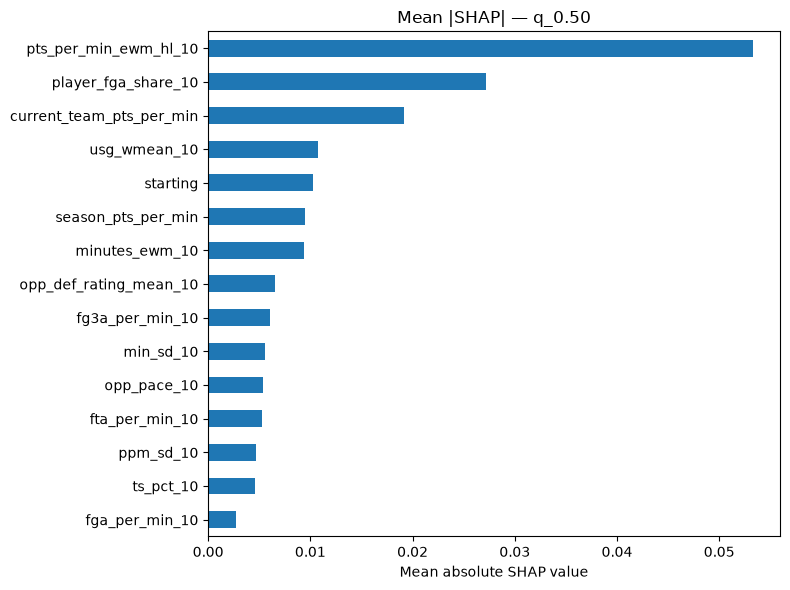

In [84]:
feat_imp = mean_absolute_shap(models_last["q_0.50"], X_val_last)
plot_shap(feat_imp)
plt.show()


In [85]:
pi_df, perm_result = permutation_importance_table(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
)
print(pi_df.to_string())


                     feature  importance      std  p_value  significant
1      pts_per_min_ewm_hl_10     0.00605  0.00018   0.0000         True
2        player_fga_share_10     0.00246  0.00014   0.0007         True
3   current_team_pts_per_min     0.00102  0.00008   0.0000         True
4         season_pts_per_min     0.00050  0.00005   0.0000         True
5             minutes_ewm_10     0.00038  0.00007   0.0000         True
6                   starting     0.00035  0.00006   0.0000         True
7               usg_wmean_10     0.00024  0.00005   0.0000         True
8     opp_def_rating_mean_10     0.00017  0.00003   0.0000         True
9                  ppm_sd_10     0.00010  0.00003   0.0000         True
10           fg3a_per_min_10     0.00010  0.00003   0.0000         True
11               opp_pace_10     0.00008  0.00003   0.0000         True
12            fta_per_min_10     0.00007  0.00003   0.0000         True
13                 ts_pct_10     0.00006  0.00002   0.0000      

In [86]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
ablation_df = run_feature_ablation(
    PTS_FEATURES,
    X.loc[train_mask_last],
    ppm_df.loc[train_mask_last, TARGET_COL],
    X.loc[val_mask_last],
    ppm_df.loc[val_mask_last, TARGET_COL],
    xgb_params=XGB_PARAMS,
)


Baseline pinball q50 (all features): 0.0895
                     feature  ablated_pinball  delta_pinball
1                   starting           0.0897         0.0002
2   current_team_pts_per_min           0.0897         0.0002
3      pts_per_min_ewm_hl_10           0.0896         0.0001
4         season_pts_per_min           0.0896         0.0001
5        player_fga_share_10           0.0896         0.0001
6     opp_def_rating_mean_10           0.0896         0.0001
7                opp_pace_10           0.0896         0.0001
8             fga_per_min_10           0.0895         0.0000
9             fta_per_min_10           0.0896         0.0000
10           fg3a_per_min_10           0.0895         0.0000
11                 ts_pct_10           0.0895         0.0000
12              usg_wmean_10           0.0895         0.0000
13                 ppm_sd_10           0.0896         0.0000
14            minutes_ewm_10           0.0895        -0.0000
15                 min_sd_10           0.

In [87]:
feature_audit = feature_consensus(
    list(X_val_last.columns),
    feat_imp,
    pi_df,
    perm_result.importances,
    ablation_df,
)
print(feature_audit.to_string())


                     feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus   keep
1      pts_per_min_ewm_hl_10       0.053282          1          1          0.00605              0.00018  9.011275e-46          0.0001   1.000000   1.000000   1.000000   True
2        player_fga_share_10       0.027217          2          2          0.00246              0.00014  4.764955e-38          0.0001   0.510821   0.406612   0.458716   True
3   current_team_pts_per_min       0.019136          3          3          0.00102              0.00008  1.513279e-33          0.0002   0.359156   0.168595   0.263875   True
4         season_pts_per_min       0.009504          6          4          0.00050              0.00005  1.499187e-30          0.0001   0.178373   0.082645   0.130509   True
5                   starting       0.010277          5          6          0.00035              0.00006  1.718856e-23          0.0

### Slice Analysis


In [88]:
dates = pd.to_datetime(ppm_holdout["game_date"])
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
blocks = regular_season_blocks(dates)
print("April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
calendar = pd.DataFrame(
    [slice_score(name, mask, y_ho, raw_q) for name, mask in blocks.items()]
)
display(calendar.round(3))

starting = ppm_holdout["starting"].to_numpy()
role = pd.DataFrame(
    [
        slice_score("Confirmed starter", starting == 1, y_ho, raw_q),
        slice_score("Bench", starting == 0, y_ho, raw_q),
    ]
)
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    print(
        f"  {row['slice']}: bias {row['bias']:+.3f} pts/min, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {role_reading(row)}."
    )

preds_ho_mono, shift, before, after = monotone_shift(raw_q)
print(f"Crossing before {before:.2%} of rows; after rearrangement {after:.2%}.")
display(shift.round(4))


April is late regular season, not the postseason
season_type
Regular Season    969


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,0,NaN,NaN,NaN,NaN,NaN,NaN
1,March 1–14,0,NaN,NaN,NaN,NaN,NaN,NaN
2,March 15–31,0,NaN,NaN,NaN,NaN,NaN,NaN
3,April regular season,969,0.201,0.016,0.518,0.797,0.591,0.136


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,430,0.166,0.000,0.509,0.791,0.516,0.112
1,Bench,539,0.229,0.029,0.525,0.801,0.651,0.156


  Confirmed starter: bias +0.000 pts/min, P(actual <= q50) 50.9%. q50 is near 50%, so the mean bias is skew around a calibrated median.
  Bench: bias +0.029 pts/min, P(actual <= q50) 52.5%. q50 is too high: actuals fall under the median more often than 50%.
Crossing before 4.54% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0001,0.0237
1,q_0.10,0.0001,0.0341
2,q_0.20,0.0003,0.0341
3,q_0.30,0.0002,0.0248
4,q_0.40,0.0002,0.0144
5,q_0.50,0.0001,0.0062
6,q_0.60,0.0000,0.0000
7,q_0.70,0.0000,0.0000
8,q_0.80,0.0000,0.0000
9,q_0.90,0.0000,0.0000


### Error Analysis


In [89]:
miss = build_miss_frame(df, ppm_holdout, preds_ho)
way_off = miss["abs_error"] >= 0.25
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 0.25+ points per minute ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.1f}."
)
display(miss_view(miss.nsmallest(20, "error")))
display(miss_view(miss.nlargest(20, "error")))
biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())
games = rotation_team_games(miss)
display(games.head(15).round(1))


2026-27 holdout: 271 / 969 rows missed by 0.25+ points per minute (28.0%). Median |error| 0.2.


,date,player,game,score,wl,actual_rate,minutes,pts,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,+/-,margin,last_game_rate,season_rate,pregame_|spread|,ot,hint
893,2026-10-25,Scottie Barnes,TOR @ MIN,94-117,L,0.0,27.9,0,0.6,-0.6,0–1,1,2,1,-27,-23,0.8,0.8,3.5,False,blowout rest
575,2026-10-23,Kyle Filipowski,UTA vs. NOP,120-119,W,0.0,7.6,0,0.5,-0.5,0–1,0,0,0,0,1,0.3,0.3,1.5,False,outside 10–90
594,2026-10-23,GG Jackson,MEM @ GSW,111-108,W,0.1,15.3,2,0.6,-0.5,0–1,4,1,1,5,3,0.6,0.6,4.5,False,outside 10–90
216,2026-10-21,Brice Sensabaugh,UTA @ MEM,103-123,L,0.1,13.6,2,0.6,-0.5,0–1,1,0,0,-10,-20,1.1,NaN,2.0,False,unexpected bench
508,2026-10-23,Will Riley,WAS vs. TOR,102-112,L,0.0,1.0,0,0.5,-0.5,0–1,0,0,0,1,-10,0.2,NaN,8.5,False,outside 10–90
959,2026-10-25,GG Jackson,MEM @ SAC,123-112,W,0.1,10.2,1,0.6,-0.5,0–1,0,1,0,-15,11,0.1,0.4,4.0,False,outside 10–90
100,2026-10-21,De'Anthony Melton,GSW @ LAL,105-127,L,0.0,20.8,0,0.4,-0.4,0–1,1,1,1,-16,-22,0.2,NaN,6.5,False,blowout rest
345,2026-10-22,Jamal Murray,DEN @ OKC,84-96,L,0.2,36.8,6,0.6,-0.4,0–1,2,4,1,-15,-12,0.7,NaN,8.0,False,outside 10–90
487,2026-10-23,Anthony Davis,WAS vs. TOR,102-112,L,0.3,32.4,9,0.7,-0.4,0–1,2,4,1,-13,-10,1.0,1.0,8.5,False,outside 10–90
90,2026-10-21,Cody Williams,MIN @ MIA,131-106,W,0.0,3.0,0,0.4,-0.4,0–1,0,0,0,-4,25,0.4,NaN,1.5,False,outside 10–90


,date,player,game,score,wl,actual_rate,minutes,pts,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,+/-,margin,last_game_rate,season_rate,pregame_|spread|,ot,hint
476,2026-10-23,Colin Castleton,ORL vs. MIN,93-115,L,2.0,3.5,7,0.2,1.8,0–1,1,1,0,0,-22,0.5,NaN,1.5,False,garbage time
362,2026-10-22,Ryan Nembhard,DEN @ OKC,84-96,L,2.0,1.7,5,0.3,1.7,0–1,0,0,0,5,-12,0.4,NaN,8.0,False,outside 10–90
446,2026-10-23,Moussa Cissé,DAL @ IND,121-105,W,2.0,0.9,3,0.3,1.7,0–1,0,1,0,3,16,1.2,1.2,7.0,False,garbage time
383,2026-10-23,Luka Garza,BOS vs. NYK,107-103,W,2.0,3.5,8,0.4,1.6,0–1,0,1,0,6,4,0.2,0.2,2.5,False,outside 10–90
357,2026-10-22,DaRon Holmes II,DEN @ OKC,84-96,L,1.7,1.7,3,0.2,1.5,0–1,0,0,0,5,-12,0.0,NaN,8.0,False,outside 10–90
66,2026-10-20,Ja'Kobi Gillespie,SAS vs. OKC,104-116,L,1.6,1.2,2,0.2,1.4,0–1,0,0,0,0,-12,NaN,NaN,1.0,False,outside 10–90
59,2026-10-20,David Jones Garcia,SAS vs. OKC,104-116,L,1.6,1.2,2,0.3,1.4,0–1,0,1,0,0,-12,0.0,NaN,1.0,False,outside 10–90
906,2026-10-25,Jaden Bradley,TOR @ MIN,94-117,L,1.3,4.6,6,0.0,1.3,0–1,0,2,0,9,-23,0.0,0.0,3.5,False,garbage time
304,2026-10-21,Jalen Pickett,LAC vs. SAC,121-96,W,1.5,2.0,3,0.2,1.3,0–1,0,0,0,3,25,0.4,NaN,5.0,False,garbage time
769,2026-10-24,Tobi Lawal,DAL vs. SAS,106-122,L,1.1,4.5,5,0.0,1.1,0–1,0,0,0,3,-16,0.0,0.0,15.0,False,garbage time


hint
outside 10–90       20
garbage time        12
unexpected bench     4
blowout rest         3
fouled out           1


,game_id,game_date,team_abbreviation,matchup,score,wl,n_rotation,n_off_025,mean_abs_error,margin,ot,players_off_by_0.25
25,0022600088,2026-10-21,TOR,TOR vs. CHI,135-92,W,5,4,0.3,43.0,False,"Immanuel Quickley (28 min, +0.35, 2 PF), Kawhi..."
48,0022600100,2026-10-23,NOP,NOP @ UTA,119-120,L,8,4,0.2,-1.0,False,"Jeremiah Fears (24 min, -0.33, 2 PF), Saddiq B..."
70,0022600111,2026-10-24,GSW,GSW @ PHX,122-131,L,3,3,0.3,-9.0,False,"Gary Payton II (17 min, -0.34, 0 PF), Brandon ..."
43,0022600097,2026-10-23,WAS,WAS vs. TOR,102-112,L,8,3,0.2,-10.0,False,"Will Riley (1 min, -0.47, 0 PF), Anthony Davis..."
0,0022600001,2026-10-20,BOS,BOS @ DET,113-121,L,3,2,0.4,-8.0,False,"Paul George (31 min, +0.76, 5 PF), Jayson Tatu..."
14,0022600008,2026-10-23,BOS,BOS vs. NYK,107-103,W,3,2,0.3,4.0,False,"Payton Pritchard (30 min, -0.39, 1 PF), Jayson..."
72,0022600112,2026-10-25,LAL,LAL @ UTA,132-123,W,5,2,0.3,9.0,False,"Luka Dončić (38 min, +0.51, 4 PF), Walker Kess..."
74,0022600113,2026-10-25,BKN,BKN vs. IND,109-136,L,3,2,0.3,-27.0,False,"Julius Randle (24 min, -0.30, 0 PF), Michael P..."
81,0022600116,2026-10-25,OKC,OKC vs. LAC,108-101,W,4,2,0.2,7.0,False,"Jared McCain (21 min, -0.32, 0 PF), Jalen Will..."
12,0022600007,2026-10-22,DEN,DEN @ OKC,84-96,L,4,2,0.2,-12.0,False,"Jamal Murray (37 min, -0.44, 2 PF), Nikola Jok..."


### Save Exploratory Artifact


In [90]:
metadata = exploratory_metadata(ppm_df, ppm_holdout, ho_metrics, wf_results)
display(metadata)


{'created_at': '2026-10-26T18:56:35.776087+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'pts_nba_model',
 'features': ['pts_per_min_ewm_hl_10',
  'player_fga_share_10',
  'ppm_trim_mean_20',
  'current_team_pts_per_min',
  'usg_wmean_10',
  'season_pts_per_min',
  'starting',
  'fta_per_min_10',
  'fga_per_min_10',
  'fg3a_per_min_10',
  'pts_per_min_mean_vs_opp',
  'fga_per_min_mean_vs_opp',
  'fta_per_min_mean_vs_opp',
  'fg3a_per_min_mean_vs_opp',
  'ppm_unstable',
  'opp_def_rating_mean_10',
  'min_mean_10',
  'min_sd_10',
  'minutes_ewm_10',
  'ts_pct_10',
  'opp_pace_10',
  'ppm_sd_10',
  'position_encoded'],
 'label': 'pts_per_min',
 'label_rule': 'min(pts / minutes, 6.0), minutes > 0',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1828,
  'max_depth': 3,
  'learning_rate': 0.08724457596180102,
  'su

In [91]:
save_path = save_model_bundle(
    models_ho,
    train_df=ppm_df,
    holdout_df=ppm_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=PTS_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
    calibration=calibration,
)
bundle = load_model_bundle(save_path)
assert list(X_ho.columns) == list(bundle["feature_names"])
scores = loaded_holdout_scores(bundle["quantile_models"], X_ho, y_ho)
print("Saved quantiles:", ", ".join(scores["quantiles"]))
print(f"Loaded model pinball q50 (holdout): {scores['pinball_q50']:.3f}")
print(f"Loaded model 80% coverage (holdout): {scores['coverage_80']:.1%}")
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")


Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/pts_nba_model_2026-10-25.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/pts_nba_model_2026-10-25.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 0.100
Loaded model 80% coverage (holdout): 79.7%
Trained on data up to      : 2026-04-12
Holdout through            : 2026-10-25


In [95]:
predictions = build_oos_predictions(
    wf, ppm_df, ppm_holdout, preds_ho, oof_cal=oof_cal, preds_ho_cal=preds_ho_cal
)
path = write_oos_predictions(predictions, ROOT / PREDICTIONS_PATH)
print(f"Wrote {len(predictions):,} rows to {path.relative_to(ROOT)}")
cal_cols = [column for column in predictions.columns if column.startswith("cal_q_")]
print(f"Calibrated knot columns: {len(cal_cols)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)


ValueError: expected 5 walk-forward folds, got [1, 2, 3, 4]

### Conclusion
